# Student Performance Predictor
## Machine Learning Regression Project

This project explores how academic and study-related factors relate to students' final exam scores. It demonstrates a complete beginner-friendly machine learning workflow, from data generation to model evaluation and visualization.

### Project Objectives
- Generate and inspect a structured student dataset.
- Perform Exploratory Data Analysis (EDA).
- Prepare features and a target variable.
- Train and compare Linear Regression and Random Forest models.
- Evaluate predictions using regression metrics.
- Analyze feature importance.
- Predict a score for a new student profile.
- Build a professional Student Academic Analytics Dashboard.

> **Dataset Disclaimer:** This notebook uses a synthetic dataset generated for learning and demonstration. It does not contain real student records and must not be used to make decisions about actual students.

## 1. Install Required Libraries

Run this cell once in your Jupyter environment to install the libraries used in this project.

In [1]:
# Install the packages required for data analysis, visualization, and machine learning.
%pip install numpy pandas matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Import Libraries and Configure Visualization Settings

Import the required libraries and configure a consistent style for all charts.

In [2]:
# File and folder management
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dashboard layout
from matplotlib.gridspec import GridSpec

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model saving
import joblib

# Visualization settings
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")
# Create the chart output folder before any figures are exported.
PROJECT_DIR = Path.cwd()
IMAGE_DIR = PROJECT_DIR / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
print("Chart folder:", IMAGE_DIR.resolve())

# Create project output directories.
PROJECT_DIR = Path.cwd()
IMAGE_DIR = PROJECT_DIR / "images"
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
for folder in (IMAGE_DIR, DATA_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folders are ready.")


Libraries imported successfully!
Chart folder: C:\Users\waqas\Desktop\student-performance-insights\images
Project folders are ready.


## 3. Generate the Synthetic Student Dataset

We generate 1,000 sample student records. Each record includes study habits and academic indicators.

The random seed makes the generated data reproducible, so running the notebook again produces the same dataset.

In [3]:
# Set a fixed seed to make the generated data reproducible.
np.random.seed(42)

# Define the number of synthetic student records.
n_students = 1000

# Generate input features within demonstration ranges.
study_hours = np.random.uniform(1, 10, n_students)
attendance = np.random.uniform(50, 100, n_students)
previous_score = np.random.uniform(35, 95, n_students)
sleep_hours = np.random.uniform(4, 10, n_students)
assignment_completion = np.random.uniform(40, 100, n_students)
participation = np.random.uniform(1, 10, n_students)

# Add random variation so the target is not perfectly determined by the inputs.
noise = np.random.normal(0, 5, n_students)

print("Synthetic student features generated successfully!")

Synthetic student features generated successfully!


## 4. Generate the Target Variable

The target variable is `Final_Score`. It is generated from an illustrative formula that combines the input features and random noise.

`np.clip()` keeps all generated scores within the valid range of 0 to 100.

In [4]:
# Generate final exam scores using a predefined synthetic relationship.
final_score = (
    study_hours * 3.5
    + attendance * 0.20
    + previous_score * 0.30
    + sleep_hours * 1.5
    + assignment_completion * 0.12
    + participation * 1.0
    + noise
)

# Restrict every generated score to the range from 0 to 100.
final_score = np.clip(final_score, 0, 100)

print("Target variable generated successfully!")

Target variable generated successfully!


## 5. Create the Pandas DataFrame

Combine all input features and the target variable into one structured DataFrame. Each row represents one synthetic student.

In [5]:
# Combine the generated features and target into a DataFrame.
df = pd.DataFrame({
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Previous_Score": previous_score,
    "Sleep_Hours": sleep_hours,
    "Assignment_Completion": assignment_completion,
    "Participation": participation,
    "Final_Score": final_score
})

# Round values to two decimal places for readability.
df = df.round(2)

# Display the first five student records.
df.head()

,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Completion,Participation,Final_Score
0,4.37,59.26,50.70,8.04,74.32,4.54,62.64
1,9.56,77.10,49.82,8.78,88.33,5.26,95.21
2,7.59,93.65,89.38,5.50,85.61,8.69,100.00
3,6.39,86.61,49.97,7.75,49.23,4.06,81.05
4,2.40,90.33,51.32,7.43,48.95,8.83,63.77


## 6. Save and Reload the Dataset

Save the DataFrame as a CSV file, then reload it to confirm the exported dataset can be read correctly.

In [6]:
# Save the generated dataset inside the data directory.
DATA_DIR = Path.cwd() / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
dataset_path = DATA_DIR / "student_performance_dataset.csv"
df.to_csv(dataset_path, index=False)

print("Dataset saved to:", dataset_path.resolve())

# Reload the dataset from the saved CSV file.
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset saved to: C:\Users\waqas\Desktop\student-performance-insights\data\student_performance_dataset.csv
Dataset loaded successfully!
Dataset shape: (1000, 7)


## 7. Dataset Overview and Data Quality Checks

Inspect the dataset dimensions, data types, descriptive statistics, missing values, and duplicate records.

In [7]:
# Display the number of rows and columns.
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 7


In [8]:
# Display column names, data types, and non-null record counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Study_Hours            1000 non-null   float64
 1   Attendance             1000 non-null   float64
 2   Previous_Score         1000 non-null   float64
 3   Sleep_Hours            1000 non-null   float64
 4   Assignment_Completion  1000 non-null   float64
 5   Participation          1000 non-null   float64
 6   Final_Score            1000 non-null   float64
dtypes: float64(7)
memory usage: 54.8 KB


In [9]:
# Calculate descriptive statistics for numeric columns.
df.describe().round(2)

,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Completion,Participation,Final_Score
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,5.41,75.35,65.14,6.94,69.65,5.49,77.50
std,2.63,14.61,17.44,1.72,17.21,2.60,12.40
min,1.04,50.16,35.00,4.00,40.00,1.06,41.32
25%,3.13,62.05,50.68,5.45,54.70,3.24,68.76
50%,5.48,75.94,65.04,6.90,69.68,5.42,77.64
75%,7.70,88.02,80.54,8.42,84.40,7.66,86.47
max,10.00,99.97,94.87,10.00,99.86,9.99,100.00


In [10]:
# Count missing values in each column.
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
Study_Hours              0
Attendance               0
Previous_Score           0
Sleep_Hours              0
Assignment_Completion    0
Participation            0
Final_Score              0
dtype: int64


In [11]:
# Count exact duplicate rows.
duplicates = df.duplicated().sum()

print("Duplicate records:", duplicates)

Duplicate records: 0


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand score distributions and relationships in the dataset before training machine learning models.

### 8.1 Final Score Distribution

The histogram shows how final exam scores are distributed. The KDE curve provides a smoothed representation of the distribution.

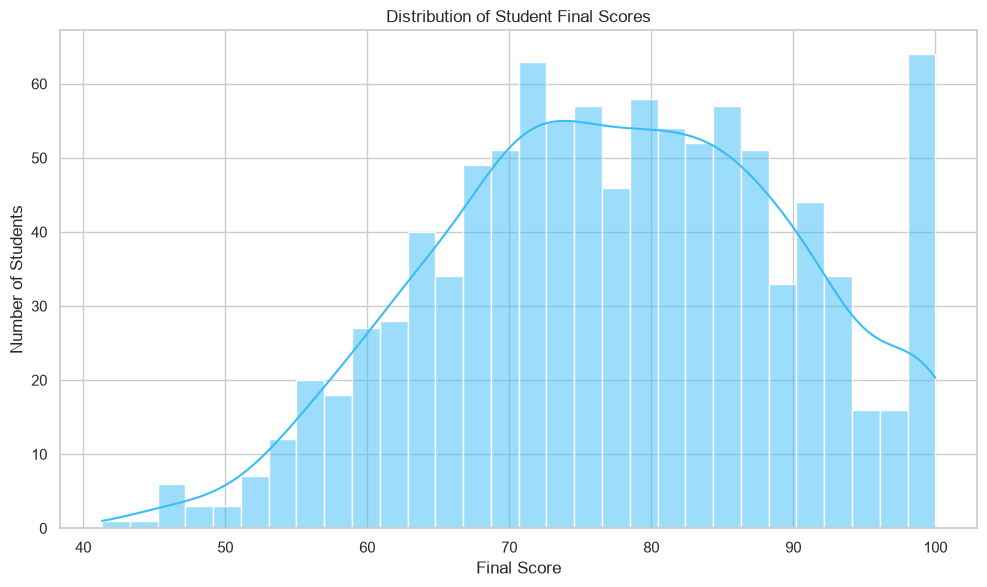

In [12]:
# Plot the distribution of final exam scores.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Final_Score",
    bins=30,
    kde=True,
    color="#38BDF8"
)

plt.title("Distribution of Student Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()

# Save the figure before displaying it.
plt.savefig("images/score_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.2 Study Hours vs. Final Score

This scatter plot explores the relationship between daily study hours and final exam scores. The regression line summarizes the overall linear trend.

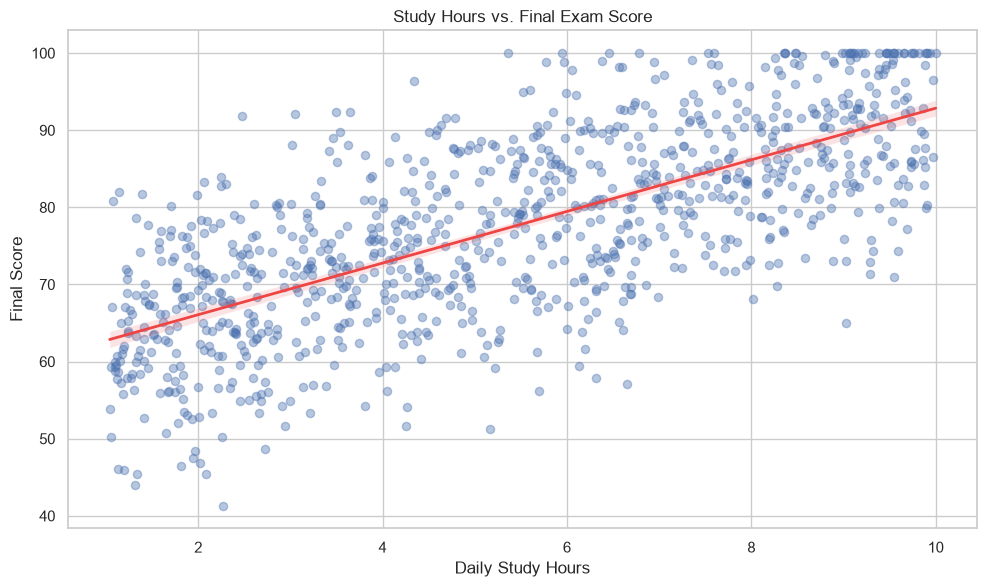

In [13]:
# Compare daily study hours with final exam scores.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Study_Hours",
    y="Final_Score",
    scatter_kws={"alpha": 0.4, "s": 35},
    line_kws={"color": "#EF4444", "linewidth": 2}
)

plt.title("Study Hours vs. Final Exam Score")
plt.xlabel("Daily Study Hours")
plt.ylabel("Final Score")
plt.tight_layout()

# Export the chart for the GitHub repository.
plt.savefig("images/study_hours_vs_score.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.3 Attendance vs. Final Score

This scatter plot shows how attendance percentages are distributed in relation to final exam scores. The color scale represents the final score.

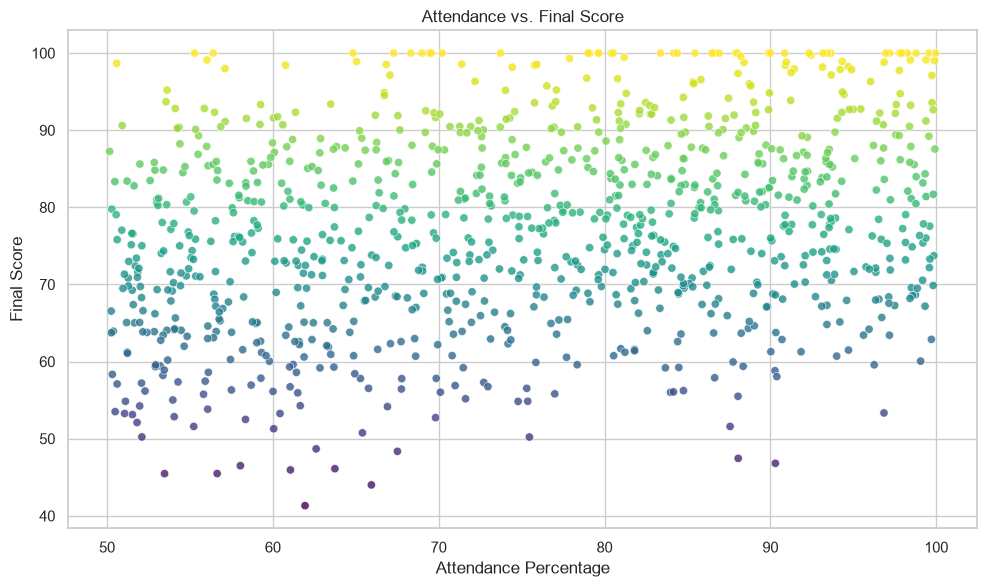

In [14]:
# Visualize the relationship between attendance and final score.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Final_Score",
    hue="Final_Score",
    palette="viridis",
    legend=False,
    alpha=0.8
)

plt.title("Attendance vs. Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")
plt.tight_layout()

# Save the attendance chart.
plt.savefig("images/attendance_vs_score.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.4 Feature Correlation Heatmap

The correlation matrix summarizes pairwise linear associations between numeric columns. Correlation does not establish causation.

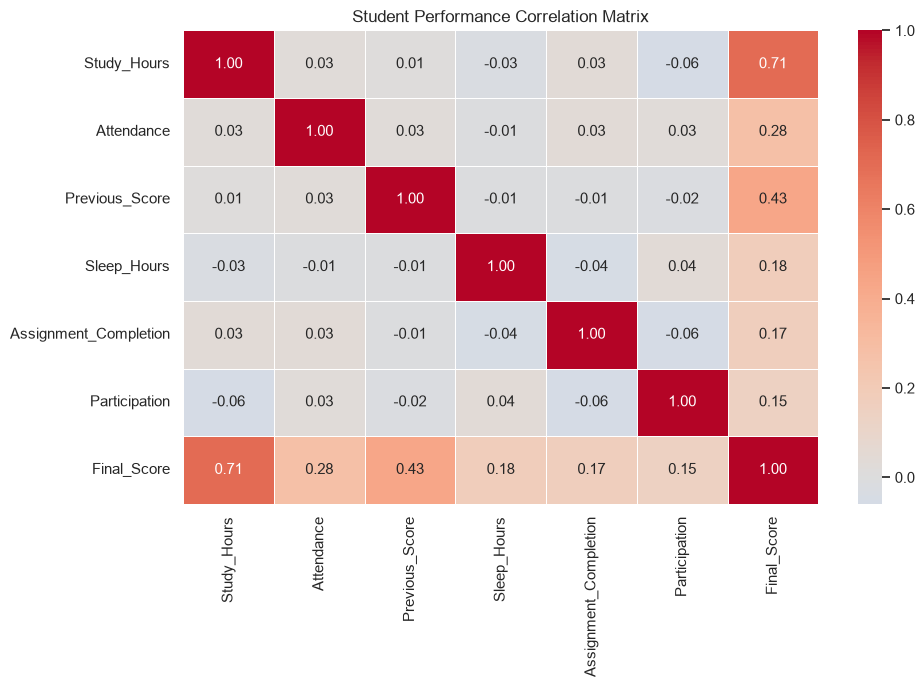

In [15]:
# Calculate correlations between numeric columns.
correlation_matrix = df.corr(numeric_only=True)

# Display correlations in an annotated heatmap.
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Student Performance Correlation Matrix")
plt.tight_layout()

# Save the heatmap for the project repository.
plt.savefig("images/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Data Preprocessing: Define Features and Target

Separate the independent variables (`X`) from the dependent variable (`y`).

- **Features (`X`):** information supplied to the machine learning model.
- **Target (`y`):** the final exam score that the model is trained to estimate.

The target column must not be included in the input features.

In [16]:
# Select the input columns by removing the target column.
X = df.drop("Final_Score", axis=1)

# Select the value that the model will predict.
y = df["Final_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 6)
Target shape: (1000,)


## 10. Split the Dataset into Training and Testing Sets

Use 80% of the records for training and keep 20% aside for testing. The test set is not used to fit the models.

In [17]:
# Split features and target into training and test subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 800
Testing samples: 200


## 11. Train Machine Learning Regression Models

We train two algorithms:

1. **Linear Regression:** a simple baseline that models a linear relationship.
2. **Random Forest Regressor:** an ensemble of decision trees that can learn more complex patterns.

### 11.1 Linear Regression

In [18]:
# Create the Linear Regression model.
linear_model = LinearRegression()

# Train the model using the training data.
linear_model.fit(X_train, y_train)

# Predict final scores for the unseen test features.
linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


### 11.2 Random Forest Regressor

In [19]:
# Create the Random Forest regression model.
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

# Train the model using the training data.
rf_model.fit(X_train, y_train)

# Generate predictions for the same held-out test set.
rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


## 12. Evaluate Model Performance

We use three regression metrics:

- **MAE:** average absolute prediction error.
- **RMSE:** square root of the mean squared prediction error; larger errors receive more weight.
- **R² Score:** compares the model with a baseline that predicts the mean target value.

Lower MAE and RMSE are generally better. An R² value closer to 1 indicates a stronger fit on the evaluated data.

In [20]:
# Define a reusable function for calculating regression metrics.
def evaluate_model(model_name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [21]:
# Evaluate Linear Regression on the test set.
linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

# Evaluate Random Forest on the same test set.
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)

# Combine the evaluation results into a comparison table.
results = pd.DataFrame([
    linear_results,
    rf_results
]).round(3)

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.162,5.278,0.824
1,Random Forest,4.489,5.617,0.800


## 13. Select the Best Model

For this introductory experiment, select the model with the lowest test MAE. Because the test results are used for selection here, this is an educational comparison. A more rigorous experiment should use a validation set or cross-validation for model selection and reserve the test set for one final evaluation.

In [22]:
# Select the model with the lower Mean Absolute Error.
best_model_name = results.sort_values(
    by="MAE",
    ascending=True
).iloc[0]["Model"]

print("Best model based on MAE:", best_model_name)

# Keep the selected model and its corresponding test predictions.
if best_model_name == "Linear Regression":
    best_model = linear_model
    best_predictions = linear_predictions
else:
    best_model = rf_model
    best_predictions = rf_predictions

print("Selected model:", best_model_name)

Best model based on MAE: Linear Regression
Selected model: Linear Regression


## 14. Actual vs. Predicted Score Visualization

Each point represents one test-set student. The diagonal reference line represents a perfect prediction. Points closer to the line indicate smaller prediction errors.

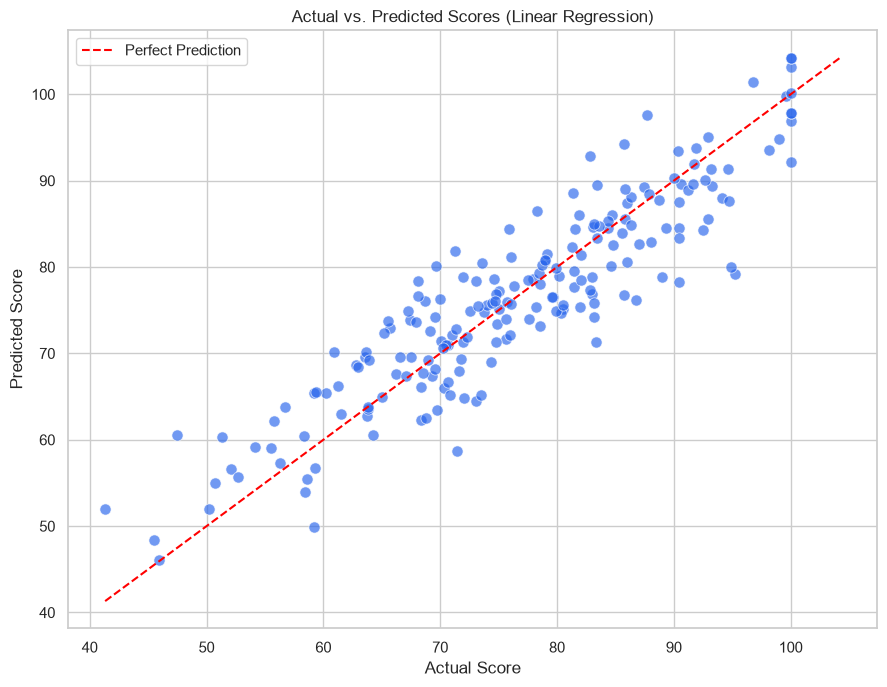

In [23]:
# Plot actual scores against the model's predicted scores.
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.65,
    s=65,
    color="#2563EB"
)

# Calculate plot limits so the reference line covers all displayed points.
min_score = min(y_test.min(), best_predictions.min())
max_score = max(y_test.max(), best_predictions.max())

# Add a diagonal line representing perfect predictions.
plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.title(f"Actual vs. Predicted Scores ({best_model_name})")
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.legend()
plt.tight_layout()

# Save the prediction comparison chart.
plt.savefig("images/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Feature Importance Analysis

Random Forest provides impurity-based feature importance values. These values describe how the fitted tree ensemble used the features; they do not prove that a feature causes a change in student performance.

In [24]:
# Create a DataFrame containing Random Forest feature importance values.
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort the features from highest to lowest importance.
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Study_Hours,0.557767
2,Previous_Score,0.210052
1,Attendance,0.076813
5,Participation,0.063289
3,Sleep_Hours,0.051900
4,Assignment_Completion,0.040179


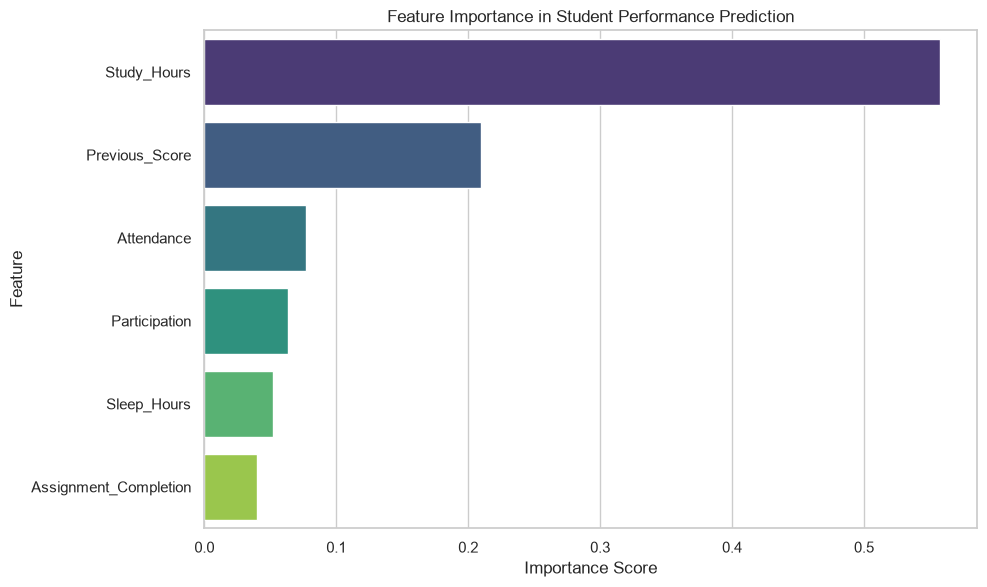

In [25]:
# Display feature importance as a horizontal bar chart.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False,
    palette="viridis"
)

plt.title("Feature Importance in Student Performance Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

# Save the feature importance chart.
plt.savefig("images/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 16. Predict the Score of a New Student

Create a new student record with the same feature names used during training. The selected model estimates the final score.

In [26]:
# Create a sample student profile for prediction.
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Score": [72],
    "Sleep_Hours": [7],
    "Assignment_Completion": [90],
    "Participation": [8]
})

# Generate a prediction and keep the displayed score within 0–100.
predicted_score = best_model.predict(new_student)[0]
predicted_score = np.clip(predicted_score, 0, 100)

print(f"Predicted Final Score: {predicted_score:.2f}")

Predicted Final Score: 88.57


### 16.1 Assign a Performance Category

The following categories are simple illustrative labels for this project. They are not official academic grading standards.

In [27]:
# Convert a numeric score into an illustrative performance category.
def get_performance_category(score):
    if score >= 85:
        return "Excellent"
    elif score >= 70:
        return "Good"
    elif score >= 50:
        return "Average"
    else:
        return "Needs Improvement"

# Display the predicted score and its category.
category = get_performance_category(predicted_score)

print("Predicted Score:", round(predicted_score, 2))
print("Performance Category:", category)

Predicted Score: 88.57
Performance Category: Excellent


## 17. Create a Reusable Student Prediction Function

This function accepts the six student features, creates a correctly structured DataFrame, and returns a predicted score.

In [28]:
# Create a reusable function for predicting one student's final score.
def predict_student_score(
    study_hours,
    attendance,
    previous_score,
    sleep_hours,
    assignment_completion,
    participation
):
    # Arrange inputs in the same column order used during model training.
    student = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Score": [previous_score],
        "Sleep_Hours": [sleep_hours],
        "Assignment_Completion": [assignment_completion],
        "Participation": [participation]
    })

    # Generate a prediction and constrain it to the 0–100 range.
    prediction = best_model.predict(student)[0]
    prediction = np.clip(prediction, 0, 100)

    # Convert the predicted score into an illustrative category.
    student_category = get_performance_category(prediction)

    # Print a formatted student performance report.
    print("=" * 45)
    print("STUDENT PERFORMANCE REPORT")
    print("=" * 45)
    print(f"Study Hours: {study_hours}")
    print(f"Attendance: {attendance}%")
    print(f"Previous Score: {previous_score}")
    print(f"Sleep Hours: {sleep_hours}")
    print(f"Assignment Completion: {assignment_completion}%")
    print(f"Participation: {participation}/10")
    print("-" * 45)
    print(f"Predicted Final Score: {prediction:.2f}/100")
    print(f"Performance Category: {student_category}")
    print("=" * 45)

    return prediction

In [29]:
# Test the reusable prediction function with a sample student.
sample_prediction = predict_student_score(
    study_hours=7,
    attendance=90,
    previous_score=80,
    sleep_hours=8,
    assignment_completion=95,
    participation=9
)

STUDENT PERFORMANCE REPORT
Study Hours: 7
Attendance: 90%
Previous Score: 80
Sleep Hours: 8
Assignment Completion: 95%
Participation: 9/10
---------------------------------------------
Predicted Final Score: 98.33/100
Performance Category: Excellent


## 18. Model Performance Comparison Visualization

Compare MAE and RMSE for both models. Both metrics are measured in score points, and lower values indicate smaller prediction errors.

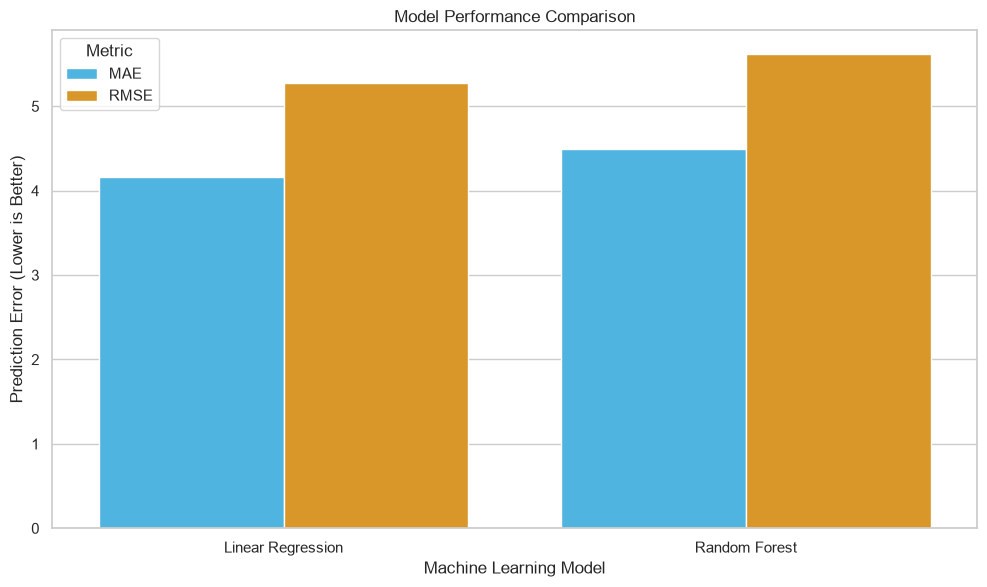

In [30]:
# Convert the model results into long format for grouped plotting.
comparison_data = results.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

# Compare MAE and RMSE for each regression model.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_data,
    x="Model",
    y="Error",
    hue="Metric",
    palette=["#38BDF8", "#F59E0B"]
)

plt.title("Model Performance Comparison")
plt.ylabel("Prediction Error (Lower is Better)")
plt.xlabel("Machine Learning Model")
plt.tight_layout()

# Save the model comparison chart.
plt.savefig("images/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 19. Build the Student Academic Analytics Dashboard

This dashboard includes KPI cards, colorful charts, a correlation heatmap, prediction comparison, feature importance, and model comparison.

All dashboard values are calculated from the generated student dataset and trained models.

C:\Users\waqas\AppData\Local\Temp\ipykernel_1308\4149566401.py:271: UserWarning: The palette list has more values (5) than needed (2), which may not be intended.
  sns.barplot(


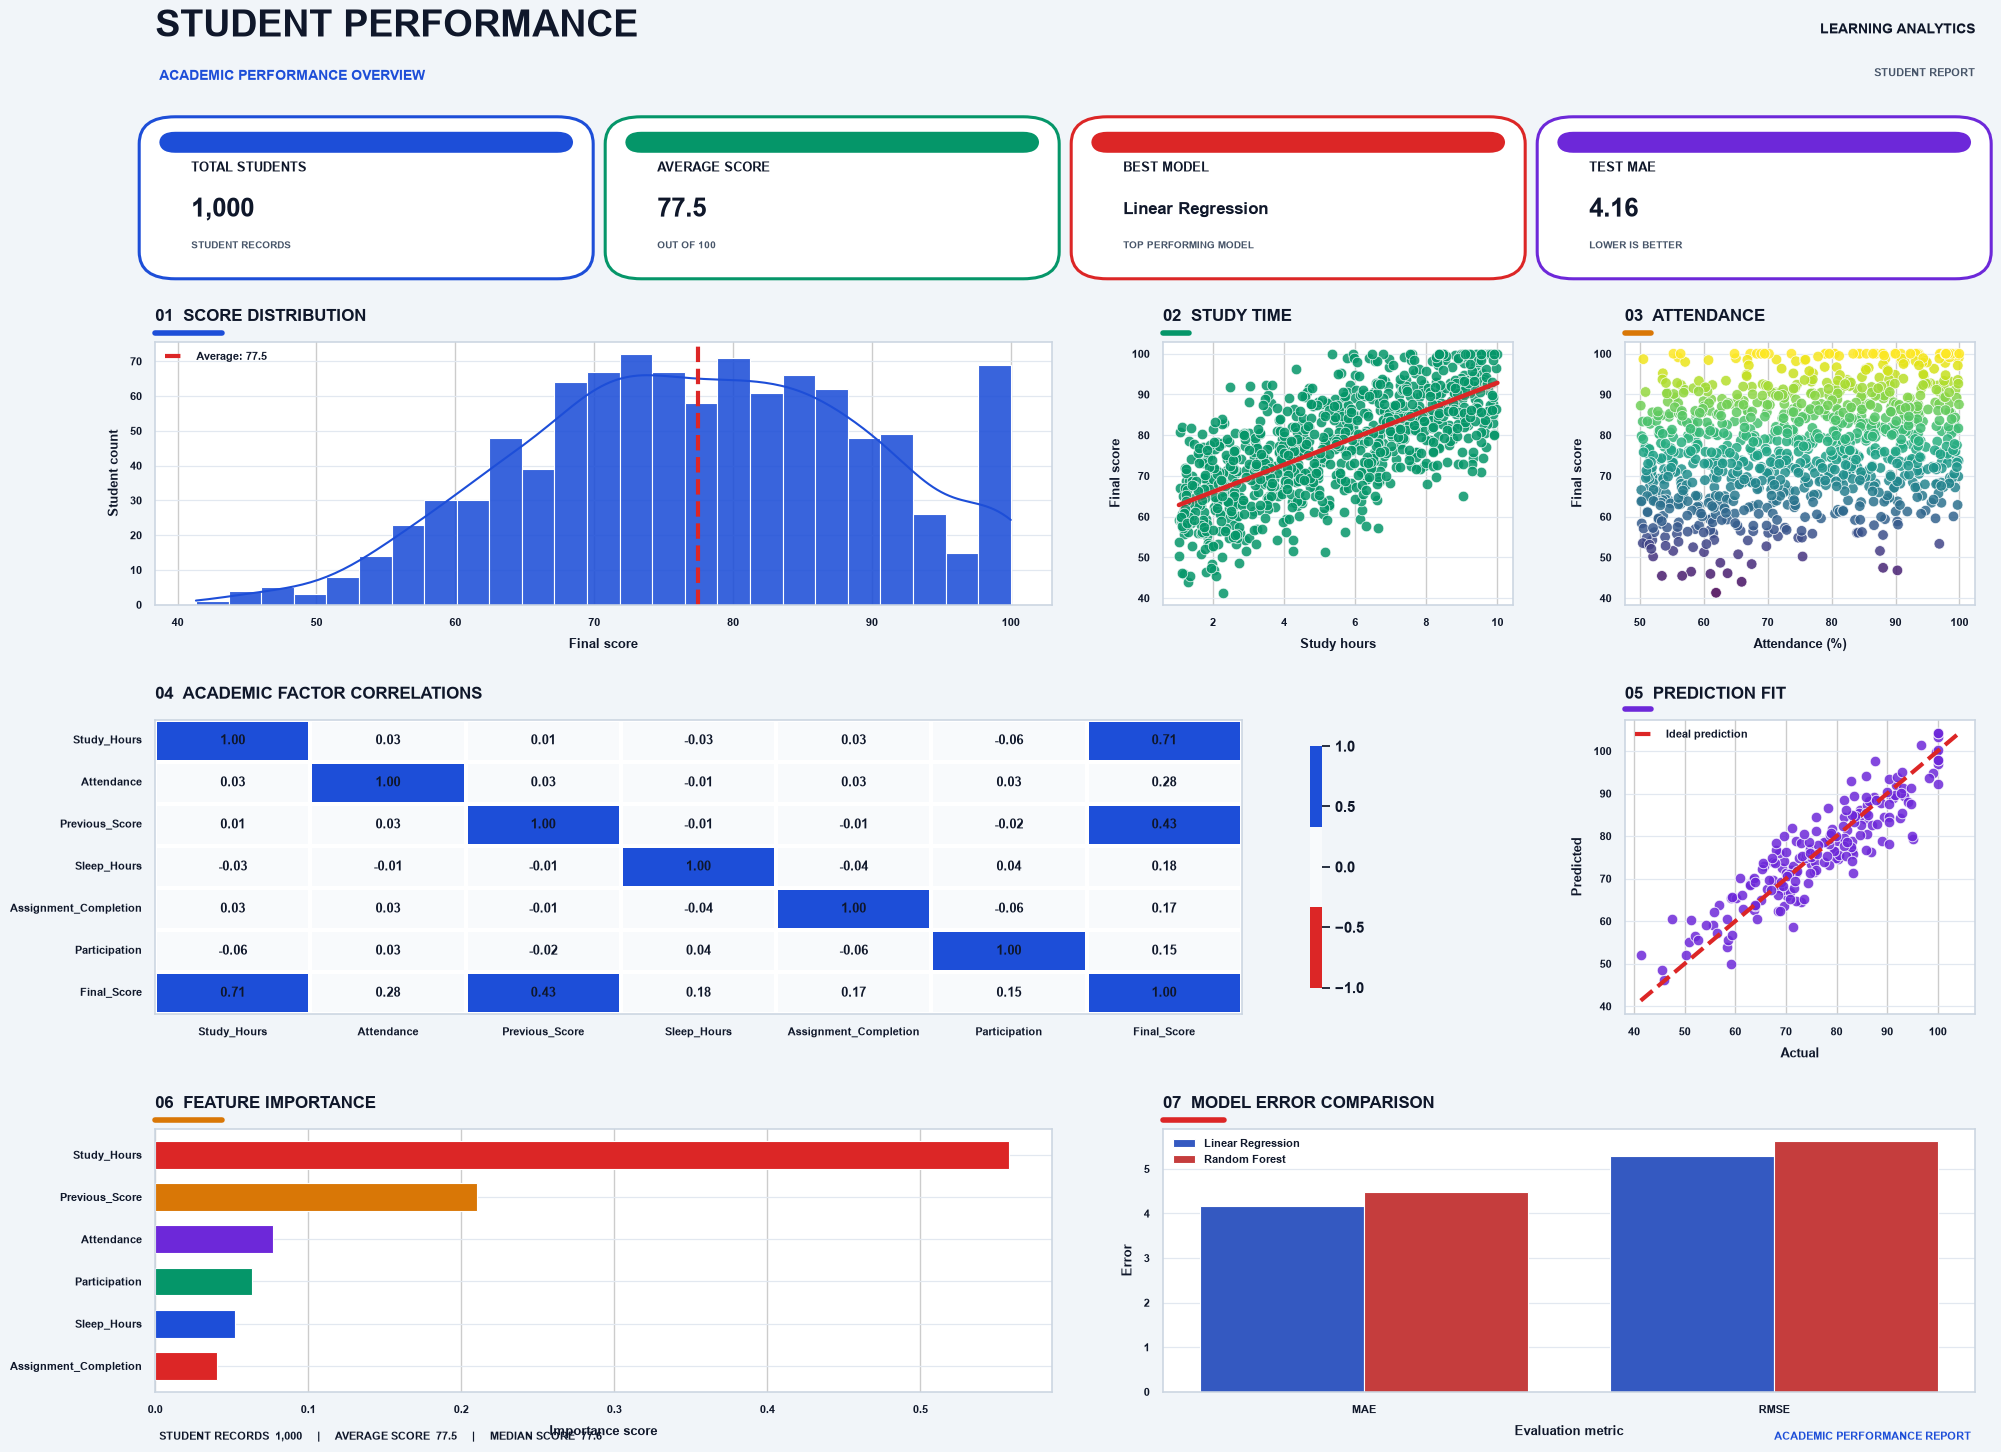

Dashboard saved to: C:\Users\waqas\Desktop\student-performance-insights\images\student_performance_dashboard.png


In [31]:
# ------------------------- Student Performance Dashboard -------------------------

from matplotlib.patches import FancyBboxPatch

# High-contrast palette
CANVAS = "#F1F5F9"
WHITE = "#FFFFFF"
CHARCOAL = "#0F172A"
MUTED = "#475569"
BORDER = "#CBD5E1"
CRIMSON = "#DC2626"
ROYAL = "#1D4ED8"
EMERALD = "#059669"
PURPLE = "#6D28D9"
AMBER = "#D97706"
PALETTE = [CRIMSON, ROYAL, EMERALD, PURPLE, AMBER]

# Keep all exported figures together.
IMAGE_DIR = Path.cwd() / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Existing model and dataset metrics.
selected_mae = results.loc[
    results["Model"] == best_model_name, "MAE"
].iloc[0]
average_score = df["Final_Score"].mean()
median_score = df["Final_Score"].median()
top_feature = feature_importance.iloc[0]["Feature"]

# Global typography: strong, dark, and consistent.
plt.rcParams.update({
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "text.color": CHARCOAL,
    "axes.labelcolor": CHARCOAL,
    "xtick.color": CHARCOAL,
    "ytick.color": CHARCOAL,
})

fig = plt.figure(figsize=(20, 15), facecolor=CANVAS)

# Header — compact editorial style.
fig.text(
    0.045, 0.965, "STUDENT PERFORMANCE",
    fontsize=27, fontweight="bold", color=CHARCOAL,
    ha="left", va="center"
)
fig.text(
    0.047, 0.932, "ACADEMIC PERFORMANCE OVERVIEW",
    fontsize=10, fontweight="bold", color=ROYAL,
    ha="left", va="center"
)
fig.text(
    0.955, 0.963, "LEARNING ANALYTICS",
    fontsize=10, fontweight="bold", color=CHARCOAL,
    ha="right", va="center"
)
fig.text(
    0.955, 0.934, "STUDENT REPORT",
    fontsize=8, fontweight="bold", color=MUTED,
    ha="right", va="center"
)

# Four redesigned KPI tiles: oversized values, bold color bars, and clear hierarchy.
kpis = [
    ("TOTAL STUDENTS", f"{len(df):,}", "STUDENT RECORDS", ROYAL),
    ("AVERAGE SCORE", f"{average_score:.1f}", "OUT OF 100", EMERALD),
    ("BEST MODEL", str(best_model_name), "TOP PERFORMING MODEL", CRIMSON),
    ("TEST MAE", f"{selected_mae:.2f}", "LOWER IS BETTER", PURPLE),
]

kpi_positions = [0.045, 0.278, 0.511, 0.744]
for i, (label, value, note, accent) in enumerate(kpis):
    x = kpi_positions[i]
    y = 0.805
    w, h = 0.211, 0.092

    # Rounded white card with a bold accent edge.
    card = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.008,rounding_size=0.018",
        transform=fig.transFigure,
        facecolor=WHITE, edgecolor=accent,
        linewidth=2.2, zorder=2
    )
    fig.add_artist(card)

    # Accent band along the top edge.
    band = FancyBboxPatch(
        (x + 0.004, y + h - 0.014), w - 0.008, 0.010,
        boxstyle="round,pad=0.002,rounding_size=0.008",
        transform=fig.transFigure,
        facecolor=accent, edgecolor=accent,
        linewidth=0, zorder=3
    )
    fig.add_artist(band)

    fig.text(
        x + 0.018, y + 0.066, label,
        fontsize=9, fontweight="bold", color=CHARCOAL,
        ha="left", va="center", zorder=4
    )
    fig.text(
        x + 0.018, y + 0.038, value,
        fontsize=19 if len(str(value)) < 12 else 12,
        fontweight="bold", color=CHARCOAL,
        ha="left", va="center", zorder=4
    )
    fig.text(
        x + 0.018, y + 0.014, note,
        fontsize=7, fontweight="bold", color=MUTED,
        ha="left", va="center", zorder=4
    )

# Bento chart grid: varied panel sizes create a different overall silhouette.
gs = GridSpec(
    3, 4, figure=fig,
    left=0.045, right=0.955,
    bottom=0.055, top=0.755,
    width_ratios=[1.12, 1.12, 1, 1],
    height_ratios=[1, 1.12, 1],
    wspace=0.30, hspace=0.42
)

def style_bento(ax, title, xlabel=None, ylabel=None, accent=ROYAL):
    ax.set_facecolor(WHITE)
    ax.set_title(
        title, loc="left", fontsize=12,
        fontweight="bold", color=CHARCOAL, pad=15
    )
    if xlabel:
        ax.set_xlabel(
            xlabel, fontsize=9, fontweight="bold",
            color=CHARCOAL, labelpad=7
        )
    if ylabel:
        ax.set_ylabel(
            ylabel, fontsize=9, fontweight="bold",
            color=CHARCOAL, labelpad=7
        )

    ax.tick_params(axis="both", colors=CHARCOAL, labelsize=8, width=1.2)
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")
        tick.set_color(CHARCOAL)

    ax.grid(axis="y", color="#E2E8F0", linewidth=0.9)
    ax.set_axisbelow(True)

    # White card with a crisp colored outline.
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color(BORDER)
        ax.spines[side].set_linewidth(1.15)

    # Colored title marker.
    ax.plot(
        [0.00, 0.075], [1.035, 1.035],
        transform=ax.transAxes, color=accent,
        linewidth=4, solid_capstyle="round", clip_on=False
    )

# 1 — Score distribution (wide panel).
ax1 = fig.add_subplot(gs[0, 0:2])
sns.histplot(
    data=df, x="Final_Score", bins=25, kde=True,
    color=ROYAL, alpha=0.88, edgecolor=WHITE,
    linewidth=0.8, ax=ax1
)
ax1.axvline(
    average_score, color=CRIMSON, linestyle="--",
    linewidth=3, label=f"Average: {average_score:.1f}"
)
style_bento(ax1, "01  SCORE DISTRIBUTION", "Final score", "Student count", ROYAL)
ax1.legend(frameon=False, fontsize=8, labelcolor=CHARCOAL)
for t in ax1.get_legend().get_texts():
    t.set_fontweight("bold")

# 2 — Study hours relationship.
ax2 = fig.add_subplot(gs[0, 2])
sns.scatterplot(
    data=df, x="Study_Hours", y="Final_Score",
    color=EMERALD, alpha=0.85, s=58,
    edgecolor=WHITE, linewidth=0.55, ax=ax2
)
sns.regplot(
    data=df, x="Study_Hours", y="Final_Score",
    scatter=False, color=CRIMSON,
    line_kws={"linewidth": 3.2}, ax=ax2
)
style_bento(ax2, "02  STUDY TIME", "Study hours", "Final score", EMERALD)

# 3 — Attendance relationship.
ax3 = fig.add_subplot(gs[0, 3])
sns.scatterplot(
    data=df, x="Attendance", y="Final_Score",
    hue="Final_Score", palette="viridis",
    legend=False, alpha=0.85, s=58,
    edgecolor=WHITE, linewidth=0.55, ax=ax3
)
style_bento(ax3, "03  ATTENDANCE", "Attendance (%)", "Final score", AMBER)

# 4 — Correlation heatmap (wide bento panel).
ax4 = fig.add_subplot(gs[1, 0:3])
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f",
    cmap=sns.color_palette(
        [CRIMSON, "#F8FAFC", ROYAL], as_cmap=True
    ),
    center=0, vmin=-1, vmax=1,
    linewidths=1.5, linecolor=WHITE,
    cbar_kws={"shrink": 0.82},
    annot_kws={
        "fontsize": 9, "fontweight": "bold",
        "color": CHARCOAL
    },
    ax=ax4
)
ax4.set_title(
    "04  ACADEMIC FACTOR CORRELATIONS",
    loc="left", fontsize=12, fontweight="bold",
    color=CHARCOAL, pad=15
)
ax4.tick_params(colors=CHARCOAL, labelsize=8, width=1.2)
for tick in ax4.get_xticklabels() + ax4.get_yticklabels():
    tick.set_fontweight("bold")
    tick.set_color(CHARCOAL)
for spine in ax4.spines.values():
    spine.set_visible(True)
    spine.set_color(BORDER)
    spine.set_linewidth(1.15)

# 5 — Actual vs predicted scores.
ax5 = fig.add_subplot(gs[1, 3])
ax5.scatter(
    y_test, best_predictions, alpha=0.85, s=58,
    color=PURPLE, edgecolors=WHITE, linewidths=0.65
)
ax5.plot(
    [min_score, max_score], [min_score, max_score],
    linestyle="--", color=CRIMSON, linewidth=3,
    label="Ideal prediction"
)
style_bento(ax5, "05  PREDICTION FIT", "Actual", "Predicted", PURPLE)
ax5.legend(frameon=False, fontsize=8, labelcolor=CHARCOAL)
for t in ax5.get_legend().get_texts():
    t.set_fontweight("bold")

# 6 — Feature importance.
ax6 = fig.add_subplot(gs[2, 0:2])
importance_sorted = feature_importance.sort_values(
    by="Importance", ascending=True
)
feature_colors = [
    PALETTE[i % len(PALETTE)]
    for i in range(len(importance_sorted))
]
ax6.barh(
    importance_sorted["Feature"],
    importance_sorted["Importance"],
    color=feature_colors, height=0.66,
    edgecolor=WHITE, linewidth=0.8
)
style_bento(ax6, "06  FEATURE IMPORTANCE", "Importance score", None, AMBER)
for tick in ax6.get_yticklabels():
    tick.set_fontweight("bold")

# 7 — Model error comparison.
ax7 = fig.add_subplot(gs[2, 2:4])
sns.barplot(
    data=comparison_data, x="Metric", y="Error",
    hue="Model", palette=[ROYAL, CRIMSON, EMERALD, PURPLE, AMBER],
    edgecolor=WHITE, linewidth=0.8, ax=ax7
)
style_bento(ax7, "07  MODEL ERROR COMPARISON", "Evaluation metric", "Error", CRIMSON)
ax7.legend(frameon=False, fontsize=8, labelcolor=CHARCOAL)
for t in ax7.get_legend().get_texts():
    t.set_fontweight("bold")

# Footer.
fig.text(
    0.047, 0.025,
    f"STUDENT RECORDS  {len(df):,}     |     AVERAGE SCORE  {average_score:.1f}     |     MEDIAN SCORE  {median_score:.1f}",
    fontsize=8, fontweight="bold", color=CHARCOAL,
    ha="left", va="center"
)
fig.text(
    0.953, 0.025, "ACADEMIC PERFORMANCE REPORT",
    fontsize=8, fontweight="bold", color=ROYAL,
    ha="right", va="center"
)

# Export the redesigned dashboard.
dashboard_path = IMAGE_DIR / "student_performance_dashboard.png"
plt.savefig(
    dashboard_path, dpi=300,
    bbox_inches="tight", facecolor=CANVAS
)
plt.show()

print("Dashboard saved to:", dashboard_path.resolve())


## 20. Save the Trained Machine Learning Model

Save the selected fitted model as a `.pkl` file. The model can be loaded later without repeating the training process.

Only load serialized model files from sources you trust.

In [32]:
# Save the selected trained model inside the models directory.
MODEL_DIR = Path.cwd() / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "student_performance_model.pkl"
joblib.dump(best_model, model_path)

print("Model saved to:", model_path.resolve())

# Load the saved model and verify that it can make a prediction.
loaded_model = joblib.load(model_path)
test_prediction = loaded_model.predict(new_student)

print(
    "Prediction using the saved model:",
    round(float(test_prediction[0]), 2)
)


Model saved to: C:\Users\waqas\Desktop\student-performance-insights\models\student_performance_model.pkl
Prediction using the saved model: 88.57


## 21. Save and List All Project Visualizations

The charts were saved when they were created. This cell lists the exported image files for use in the GitHub repository.

In [33]:
# List all PNG charts saved in the images directory.
IMAGE_DIR = Path.cwd() / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

image_files = sorted(IMAGE_DIR.glob("*.png"))

print("Exported visualization files:")
if image_files:
    for image_file in image_files:
        print("-", image_file.resolve())
else:
    print("No PNG charts found yet. Run the visualization cells first.")

print("\nDashboard image:")
dashboard_file = IMAGE_DIR / "student_performance_dashboard.png"
print(dashboard_file.resolve())
print("Dashboard exists:", dashboard_file.exists())


Exported visualization files:
- C:\Users\waqas\Desktop\student-performance-insights\images\actual_vs_predicted.png
- C:\Users\waqas\Desktop\student-performance-insights\images\attendance_vs_score.png
- C:\Users\waqas\Desktop\student-performance-insights\images\correlation_heatmap.png
- C:\Users\waqas\Desktop\student-performance-insights\images\feature_importance.png
- C:\Users\waqas\Desktop\student-performance-insights\images\model_comparison.png
- C:\Users\waqas\Desktop\student-performance-insights\images\score_distribution.png
- C:\Users\waqas\Desktop\student-performance-insights\images\student_performance_dashboard.png
- C:\Users\waqas\Desktop\student-performance-insights\images\study_hours_vs_score.png

Dashboard image:
C:\Users\waqas\Desktop\student-performance-insights\images\student_performance_dashboard.png
Dashboard exists: True


## 22. Final Project Summary

Display the dataset size, selected model, and final test-set evaluation metrics in a compact report.

In [34]:
# Retrieve the selected model's evaluation results.
selected_results = results[
    results["Model"] == best_model_name
].iloc[0]

# Print a formatted project summary.
print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION PROJECT")
print("=" * 55)
print(f"Dataset Size: {len(df)} students")
print(f"Number of Input Features: {X.shape[1]}")
print(f"Selected Model: {best_model_name}")
print(f"MAE: {selected_results['MAE']:.3f}")
print(f"RMSE: {selected_results['RMSE']:.3f}")
print(f"R2 Score: {selected_results['R2 Score']:.3f}")
print("=" * 55)

STUDENT PERFORMANCE PREDICTION PROJECT
Dataset Size: 1000 students
Number of Input Features: 6
Selected Model: Linear Regression
MAE: 4.162
RMSE: 5.278
R2 Score: 0.824


## 23. Conclusion and Future Improvements

This project demonstrates an introductory end-to-end regression workflow, from synthetic data generation and exploratory data analysis to model training, evaluation, prediction, and dashboard visualization.

### Limitations
- The dataset is synthetic and follows a predefined score-generation formula.
- Evaluation results apply to this generated dataset only.
- Correlation and feature importance do not establish causation.
- Selecting a model based on test results can make the reported test metrics optimistic.

### Future Improvements
- Repeat the experiment with a documented public academic dataset.
- Use cross-validation or a validation set for model selection.
- Add hyperparameter tuning and residual analysis.
- Build an interactive Streamlit application.
- Investigate explainability and responsible use before applying the model to real student data.